In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim

from tqdm import tqdm
from matplotlib import pyplot as plt

# PARAMETRI

In [3]:
EPOCHS = 10
BATCH_SIZE = 256
LEARNING_RATE = 0.001
DEVICE = torch.accelerator.current_accelerator() if torch.accelerator.is_available() else torch.DEVICE('cpu')

print(f"DEVICE: {DEVICE}")

DEVICE: cuda


# DATASET

TRAIN SET shape: torch.Size([60000, 28, 28])
TEST SET shape:  torch.Size([10000, 28, 28])


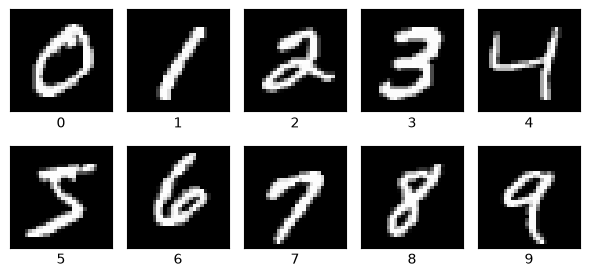

In [4]:
from datasets.datasets import load_MNIST
train_dataset, test_dataset, train_loader, test_loader = load_MNIST(batch_size=BATCH_SIZE, verbose=False)

print(f"TRAIN SET shape: {train_dataset.data.shape}")
print(f"TEST SET shape:  {test_dataset.data.shape}")

plt.figure(figsize=(6, 3))
for c in range(len(train_dataset.classes)):
    idx = (train_dataset.targets == c).nonzero()[0].item()   # primo esempio della classe c
    img, label = train_dataset[idx]
    plt.subplot(2, 5, c + 1)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(img.squeeze(), cmap="gray")
    plt.xlabel(label)
plt.tight_layout()
plt.show()

# MODELL0

In [5]:
model = nn.Sequential(
            nn.Flatten(),    
            nn.Linear(28*28,16),
            nn.ReLU(),
            nn.Linear(16, 16),
            nn.ReLU(),
            nn.Linear(16, 16),
            nn.ReLU(),
            nn.Linear(16, 16),
            nn.ReLU(),
            nn.Linear(16, 10),
            # nn.Softmax(dim=1)
        )
model.to(DEVICE)
model

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=16, bias=True)
  (2): ReLU()
  (3): Linear(in_features=16, out_features=16, bias=True)
  (4): ReLU()
  (5): Linear(in_features=16, out_features=16, bias=True)
  (6): ReLU()
  (7): Linear(in_features=16, out_features=16, bias=True)
  (8): ReLU()
  (9): Linear(in_features=16, out_features=10, bias=True)
)

$$\text{Softmax}(z_i) = \frac{e^{z_i}}{\sum_{j=1}^{K} e^{z_j}} \quad \text{per } i = 1, \dots, K$$

In [6]:
criterion = nn.CrossEntropyLoss()

$$y_i = [0,0,1,\dots,0,0] \rightarrow CATEGORICAL: \mathcal{L} = -\frac{1}{N} \sum_{i=1}^{N} \sum_{c=1}^{C} y_{i,c} \log(\hat{y}_{i,c})$$

$$y_i = 2 \rightarrow SPARSE:\qquad \mathcal{L} = -\frac{1}{N} \sum_{i=1}^{N} \log(\hat{y}_{i, y_i})$$

In [7]:
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE, betas=(0.9, 0.999), eps=1e-7)

# ADDESTRAMENTO

In [22]:
total = len(train_loader.dataset)

for epoch in range(EPOCHS):
    epoch_loss = 0
    correct = 0

    for train_images, train_labels in tqdm(train_loader):
        optimizer.zero_grad()
        
        train_images = train_images.to(DEVICE)
        train_labels = train_labels.to(DEVICE)
        
        outputs = model(train_images)
        loss = criterion(outputs, train_labels)

        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

        _, predicted = torch.max(outputs, 1)
        correct += (predicted == train_labels).sum().item()

    train_loss = epoch_loss / len(train_loader)
    train_accuracy = 100 * correct / total
    print(f"Epoch [{epoch+1}/{EPOCHS}], Loss: {train_loss:.4f}, Accuracy: {train_accuracy:.2f}%")

# filename = "TDB"
# torch.save(model.state_dict(), filename)
#model = torch.load(PATH, weights_only=False)
#model.eval()

100%|██████████| 235/235 [00:07<00:00, 32.55it/s]


Epoch [1/10], Loss: 0.1805, Accuracy: 94.75%


100%|██████████| 235/235 [00:07<00:00, 32.98it/s]


Epoch [2/10], Loss: 0.1760, Accuracy: 94.85%


 39%|███▊      | 91/235 [00:02<00:04, 32.43it/s]


KeyboardInterrupt: 

# VALUTAZIONE

In [21]:
model.eval()

test_loss = 0
correct = 0
total = len(test_loader.dataset)

with torch.no_grad():
    for test_images, test_labels in tqdm(test_loader):
        test_images = test_images.to(DEVICE)
        test_labels = test_labels.to(DEVICE)

        outputs = model(test_images)
        loss = criterion(outputs, test_labels)

        _, predicted = torch.max(outputs, 1)
        correct += (predicted == test_labels).sum().item()
        test_loss += loss.item()

test_loss = test_loss / total
test_accuracy = 100 * correct / total
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy:.2f}%")

100%|██████████| 40/40 [00:01<00:00, 36.71it/s]

Test Loss: 0.0008, Test Accuracy: 94.04%
